<a href="https://colab.research.google.com/github/Srushti328/AutoDataIQ/blob/main/RVITM_Online_Food_Delivery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install PySpark in Google Colab
!pip -q install pyspark
print("PySpark installation finished")

PySpark installation finished


In [ ]:
# Import the required packages
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, sum, avg, min, max, round, desc, when
)
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Packages imported successfully")

Packages imported successfully


In [ ]:
# Create a Spark session
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("FoodDeliveryAnalysis")
    .getOrCreate()
)
print("Spark is ready")
print("Spark version:", spark.version)

Spark is ready
Spark version: 4.0.5


In [ ]:
food_data = """order_id,customer,restaurant,item,quantity,item_price,delivery_time,rating,city
O001,Aarav,Food Corner,Burger,2,8.50,28,5,Bengaluru
O002,Diya,Pizza Hub,Pizza,1,15.00,35,4,Mysuru
O003,Rohan,Food Corner,French Fries,3,4.00,22,4,Bengaluru
O004,Ananya,South Kitchen,Dosa,2,5.50,25,5,Chennai
O005,Vikram,Pizza Hub,Pizza,2,15.00,40,3,Bengaluru
O006,Meera,South Kitchen,Idli,4,3.00,20,5,Chennai
O007,Arjun,Spice House,Biryani,2,12.50,45,4,Hyderabad
O008,Isha,Food Corner,Burger,1,8.50,30,4,Mysuru
O009,Kabir,Spice House,Biryani,1,12.50,38,5,Hyderabad
O010,Saanvi,South Kitchen,Dosa,3,5.50,27,4,Bengaluru
O011,Rahul,Pizza Hub,Pasta,2,10.00,32,5,Chennai
O012,Priya,Spice House,Noodles,2,7.50,36,3,Hyderabad
O013,Neha,Food Corner,Sandwich,2,6.00,24,4,Bengaluru
O014,Aditya,Pizza Hub,Pizza,1,15.00,29,5,Mysuru
O015,Kavya,South Kitchen,Idli,3,3.00,18,4,Chennai
"""

with open("/content/food_delivery_orders.csv", "w") as file:
    file.write(food_data)

print("Dataset created successfully.")
print("File location: /content/food_delivery_orders.csv")


Dataset created successfully.
File location: /content/food_delivery_orders.csv


In [ ]:
# View the raw CSV data
with open(csv_path, "r", encoding="utf-8") as file:
    print(file.read())

order_id,customer,restaurant,item,quantity,item_price,delivery_time,rating,city
O001,Aarav,Food Corner,Burger,2,8.50,28,5,Bengaluru
O002,Diya,Pizza Hub,Pizza,1,15.00,35,4,Mysuru
O003,Rohan,Food Corner,French Fries,3,4.00,22,4,Bengaluru
O004,Ananya,South Kitchen,Dosa,2,5.50,25,5,Chennai
O005,Vikram,Pizza Hub,Pizza,2,15.00,40,3,Bengaluru
O006,Meera,South Kitchen,Idli,4,3.00,20,5,Chennai
O007,Arjun,Spice House,Biryani,2,12.50,45,4,Hyderabad
O008,Isha,Food Corner,Burger,1,8.50,30,4,Mysuru
O009,Kabir,Spice House,Biryani,1,12.50,38,5,Hyderabad
O010,Saanvi,South Kitchen,Dosa,3,5.50,27,4,Bengaluru
O011,Rahul,Pizza Hub,Pasta,2,10.00,32,5,Chennai
O012,Priya,Spice House,Noodles,2,7.50,36,3,Hyderabad
O013,Neha,Food Corner,Sandwich,2,6.00,24,4,Bengaluru
O014,Aditya,Pizza Hub,Pizza,1,15.00,29,5,Mysuru
O015,Kavya,South Kitchen,Idli,3,3.00,18,4,Chennai



In [ ]:
# Load the CSV file into a Spark DataFrame
df = spark.read.csv(
    csv_path,
    header=True,
    inferSchema=True
)
print("CSV file loaded successfully")

CSV file loaded successfully


In [ ]:
# Display the dataset
df.show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |
|O007    |Arjun   |Spice House  |Biryani     |2       |12.5      |45           |4     |Hyderabad|
|O008    |Isha    |F

In [ ]:
# Examine the DataFrame structure
print("Column names:")
print(df.columns)

print("\nData types and schema:")
df.printSchema()

print("\nNumber of rows:", df.count())

Column names:
['order_id', 'customer', 'restaurant', 'item', 'quantity', 'item_price', 'delivery_time', 'rating', 'city']

Data types and schema:
root
 |-- order_id: string (nullable = true)
 |-- customer: string (nullable = true)
 |-- restaurant: string (nullable = true)
 |-- item: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- item_price: double (nullable = true)
 |-- delivery_time: integer (nullable = true)
 |-- rating: integer (nullable = true)
 |-- city: string (nullable = true)


Number of rows: 15


In [ ]:
# Display the first record
first_order = df.first()
print(first_order)

Row(order_id='O001', customer='Aarav', restaurant='Food Corner', item='Burger', quantity=2, item_price=8.5, delivery_time=28, rating=5, city='Bengaluru')


In [ ]:
# Create total_value = quantity * item_price
df = df.withColumn(
    "total_value",
    round(col("quantity") * col("item_price"), 2)
)

print("DataFrame with total_value column:")
df.show(truncate=False)

DataFrame with total_value column:
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|17.0       |
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5    

In [ ]:
# Analysis Question 1: Count total orders
total_orders = df.count()
print("Total number of orders:", total_orders)

Total number of orders: 15


In [ ]:
# Analysis Question 2: Minimum, maximum and average order value
df.select(
    min("total_value").alias("minimum_order_value"),
    max("total_value").alias("maximum_order_value"),
    round(avg("total_value"), 2).alias("average_order_value")
).show()

+-------------------+-------------------+-------------------+
|minimum_order_value|maximum_order_value|average_order_value|
+-------------------+-------------------+-------------------+
|                8.5|               30.0|              15.37|
+-------------------+-------------------+-------------------+



In [ ]:
# Analysis Question 3: Number of orders for each food item
df.groupBy("item").agg(
    count("*").alias("number_of_orders")
).orderBy(desc("number_of_orders")).show()

+------------+----------------+
|        item|number_of_orders|
+------------+----------------+
|       Pizza|               3|
|        Idli|               2|
|        Dosa|               2|
|     Biryani|               2|
|      Burger|               2|
|    Sandwich|               1|
|French Fries|               1|
|       Pasta|               1|
|     Noodles|               1|
+------------+----------------+



In [ ]:
# Analysis Question 4: Total quantity ordered for each item
df.groupBy("item").agg(
    sum("quantity").alias("total_quantity")
).orderBy(desc("total_quantity")).show()

+------------+--------------+
|        item|total_quantity|
+------------+--------------+
|        Idli|             7|
|        Dosa|             5|
|       Pizza|             4|
|     Biryani|             3|
|      Burger|             3|
|French Fries|             3|
|    Sandwich|             2|
|       Pasta|             2|
|     Noodles|             2|
+------------+--------------+



In [ ]:
# Analysis Question 5: Orders with total value greater than $20
df.filter(col("total_value") > 20).show(truncate=False)

+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant |item   |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+
|O005    |Vikram  |Pizza Hub  |Pizza  |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O007    |Arjun   |Spice House|Biryani|2       |12.5      |45           |4     |Hyderabad|25.0       |
+--------+--------+-----------+-------+--------+----------+-------------+------+---------+-----------+



In [ ]:
# Analysis Question 6: Number of orders received by each restaurant
df.groupBy("restaurant").agg(
    count("*").alias("number_of_orders")
).orderBy(desc("number_of_orders")).show()

+-------------+----------------+
|   restaurant|number_of_orders|
+-------------+----------------+
|  Food Corner|               4|
|    Pizza Hub|               4|
|South Kitchen|               4|
|  Spice House|               3|
+-------------+----------------+



In [ ]:
# Analysis Question 7: Average delivery time for each restaurant
df.groupBy("restaurant").agg(
    round(avg("delivery_time"), 2).alias("average_delivery_minutes")
).orderBy("average_delivery_minutes").show()

+-------------+------------------------+
|   restaurant|average_delivery_minutes|
+-------------+------------------------+
|South Kitchen|                    22.5|
|  Food Corner|                    26.0|
|    Pizza Hub|                    34.0|
|  Spice House|                   39.67|
+-------------+------------------------+



In [ ]:
# Analysis Question 8: Orders with a rating of 4 or above
df.filter(col("rating") >= 4).show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|17.0       |
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O007    |Arjun   |Spice House  |Biryani     |2       |12.5      |45           |4     |Hyderabad|25.0       |
|O008    |

In [ ]:
# Step 11: Restaurant-level summary
restaurant_summary = df.groupBy("restaurant").agg(
    count("*").alias("total_orders"),
    sum("quantity").alias("total_quantity_sold"),
    round(sum("total_value"), 2).alias("total_sales"),
    round(avg("delivery_time"), 2).alias("average_delivery_time"),
    round(avg("rating"), 2).alias("average_rating")
).orderBy(desc("total_sales"))

restaurant_summary.show(truncate=False)

+-------------+------------+-------------------+-----------+---------------------+--------------+
|restaurant   |total_orders|total_quantity_sold|total_sales|average_delivery_time|average_rating|
+-------------+------------+-------------------+-----------+---------------------+--------------+
|Pizza Hub    |4           |6                  |80.0       |34.0                 |4.25          |
|Spice House  |3           |5                  |52.5       |39.67                |4.0           |
|Food Corner  |4           |8                  |49.5       |26.0                 |4.25          |
|South Kitchen|4           |12                 |48.5       |22.5                 |4.5           |
+-------------+------------+-------------------+-----------+---------------------+--------------+



In [ ]:
# Step 12: Create a temporary SQL view
df.createOrReplaceTempView("food_orders")
print("Temporary SQL view 'food_orders' created")

Temporary SQL view 'food_orders' created


In [ ]:
# Step 13: Display data using Spark SQL
spark.sql("""
    SELECT *
    FROM food_orders
    LIMIT 10
""").show(truncate=False)

+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|order_id|customer|restaurant   |item        |quantity|item_price|delivery_time|rating|city     |total_value|
+--------+--------+-------------+------------+--------+----------+-------------+------+---------+-----------+
|O001    |Aarav   |Food Corner  |Burger      |2       |8.5       |28           |5     |Bengaluru|17.0       |
|O002    |Diya    |Pizza Hub    |Pizza       |1       |15.0      |35           |4     |Mysuru   |15.0       |
|O003    |Rohan   |Food Corner  |French Fries|3       |4.0       |22           |4     |Bengaluru|12.0       |
|O004    |Ananya  |South Kitchen|Dosa        |2       |5.5       |25           |5     |Chennai  |11.0       |
|O005    |Vikram  |Pizza Hub    |Pizza       |2       |15.0      |40           |3     |Bengaluru|30.0       |
|O006    |Meera   |South Kitchen|Idli        |4       |3.0       |20           |5     |Chennai  |12.0       |
|O007    |

In [ ]:
# SQL Question 1: Total number of orders
spark.sql("""
    SELECT COUNT(*) AS total_orders
    FROM food_orders
""").show()

+------------+
|total_orders|
+------------+
|          15|
+------------+



In [ ]:
# SQL Question 2: Number of orders for each item
spark.sql("""
    SELECT item, COUNT(*) AS number_of_orders
    FROM food_orders
    GROUP BY item
    ORDER BY number_of_orders DESC
""").show()

+------------+----------------+
|        item|number_of_orders|
+------------+----------------+
|       Pizza|               3|
|        Idli|               2|
|        Dosa|               2|
|     Biryani|               2|
|      Burger|               2|
|    Sandwich|               1|
|French Fries|               1|
|       Pasta|               1|
|     Noodles|               1|
+------------+----------------+



In [ ]:
# SQL Question 3: Minimum, maximum and average order values
spark.sql("""
    SELECT
        MIN(total_value) AS minimum_order_value,
        MAX(total_value) AS maximum_order_value,
        ROUND(AVG(total_value), 2) AS average_order_value
    FROM food_orders
""").show()

+-------------------+-------------------+-------------------+
|minimum_order_value|maximum_order_value|average_order_value|
+-------------------+-------------------+-------------------+
|                8.5|               30.0|              15.37|
+-------------------+-------------------+-------------------+



In [ ]:
# SQL Question 4: Orders with total value greater than $20
spark.sql("""
    SELECT order_id, customer, restaurant, item, total_value
    FROM food_orders
    WHERE total_value > 20
    ORDER BY total_value DESC
""").show()

+--------+--------+-----------+-------+-----------+
|order_id|customer| restaurant|   item|total_value|
+--------+--------+-----------+-------+-----------+
|    O005|  Vikram|  Pizza Hub|  Pizza|       30.0|
|    O007|   Arjun|Spice House|Biryani|       25.0|
+--------+--------+-----------+-------+-----------+



In [ ]:
# SQL Question 5: Total sales for each restaurant
spark.sql("""
    SELECT restaurant, ROUND(SUM(total_value), 2) AS total_sales
    FROM food_orders
    GROUP BY restaurant
    ORDER BY total_sales DESC
""").show()

+-------------+-----------+
|   restaurant|total_sales|
+-------------+-----------+
|    Pizza Hub|       80.0|
|  Spice House|       52.5|
|  Food Corner|       49.5|
|South Kitchen|       48.5|
+-------------+-----------+



In [ ]:
# SQL Question 6: Restaurant with the lowest average delivery time
spark.sql("""
    SELECT restaurant,
           ROUND(AVG(delivery_time), 2) AS average_delivery_time
    FROM food_orders
    GROUP BY restaurant
    ORDER BY average_delivery_time ASC
    LIMIT 1
""").show()

+-------------+---------------------+
|   restaurant|average_delivery_time|
+-------------+---------------------+
|South Kitchen|                 22.5|
+-------------+---------------------+



In [ ]:
# Step 14: Prepare restaurant order counts for a bar chart
orders_per_restaurant = (
    df.groupBy("restaurant")
      .agg(count("*").alias("number_of_orders"))
      .orderBy("restaurant")
)

# Convert this small summary to Pandas for plotting
plot_df = orders_per_restaurant.toPandas()
display(plot_df)

,restaurant,number_of_orders
0,Food Corner,4
1,Pizza Hub,4
2,South Kitchen,4
3,Spice House,3


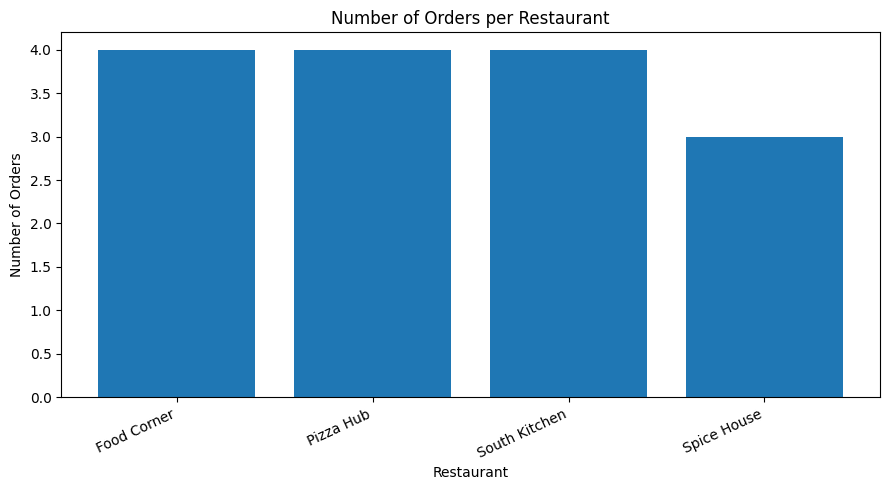

In [ ]:
# Step 15: Visualize number of orders per restaurant
plt.figure(figsize=(9, 5))
plt.bar(plot_df["restaurant"], plot_df["number_of_orders"])
plt.xlabel("Restaurant")
plt.ylabel("Number of Orders")
plt.title("Number of Orders per Restaurant")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Part D: Student Practice Exercises — solutions

# Basic Exercises
print("1. Selected columns:")
df.select("order_id", "customer", "item", "total_value").show()

print("2. Orders delivered in Bengaluru:")
df.filter(col("city") == "Bengaluru").show(truncate=False)

print("3. Pizza orders:")
df.filter(col("item") == "Pizza").show(truncate=False)

print("4. Orders with delivery time greater than 30 minutes:")
df.filter(col("delivery_time") > 30).show(truncate=False)

print("5. Orders with rating equal to 5:")
df.filter(col("rating") == 5).show(truncate=False)

# Intermediate Exercises
print("6. Number of orders from each city:")
df.groupBy("city").agg(count("*").alias("number_of_orders")).show()

print("7. Total sales generated in each city:")
df.groupBy("city").agg(round(sum("total_value"), 2).alias("total_sales")).show()

print("8. Average rating for each restaurant:")
df.groupBy("restaurant").agg(round(avg("rating"), 2).alias("average_rating")).show()

print("9. Total quantity sold by each restaurant:")
df.groupBy("restaurant").agg(sum("quantity").alias("total_quantity")).show()

print("10. Three highest-value orders:")
df.orderBy(desc("total_value")).select(
    "order_id", "customer", "restaurant", "total_value"
).show(3, truncate=False)

# Challenge Exercises
print("11. Restaurants with average rating at least 4:")
df.groupBy("restaurant").agg(
    avg("rating").alias("average_rating")
).filter(col("average_rating") >= 4).show()

print("12. Cities where total sales are greater than $50:")
df.groupBy("city").agg(
    sum("total_value").alias("total_sales")
).filter(col("total_sales") > 50).show()

print("13. Food item that generated the highest total sales:")
df.groupBy("item").agg(
    round(sum("total_value"), 2).alias("item_sales")
).orderBy(desc("item_sales")).show(1)

print("14. Customer whose order had the longest delivery time:")
df.orderBy(desc("delivery_time")).select(
    "customer", "order_id", "restaurant", "delivery_time"
).show(1, truncate=False)

print("15. Classify orders by total value:")
df_classified = df.withColumn(
    "order_category",
    when(col("total_value") < 15, "Low Value")
    .when(col("total_value") <= 25, "Medium Value")
    .otherwise("High Value")
)
df_classified.select(
    "order_id", "customer", "total_value", "order_category"
).show(truncate=False)

1. Selected columns:
+--------+--------+------------+-----------+
|order_id|customer|        item|total_value|
+--------+--------+------------+-----------+
|    O001|   Aarav|      Burger|       17.0|
|    O002|    Diya|       Pizza|       15.0|
|    O003|   Rohan|French Fries|       12.0|
|    O004|  Ananya|        Dosa|       11.0|
|    O005|  Vikram|       Pizza|       30.0|
|    O006|   Meera|        Idli|       12.0|
|    O007|   Arjun|     Biryani|       25.0|
|    O008|    Isha|      Burger|        8.5|
|    O009|   Kabir|     Biryani|       12.5|
|    O010|  Saanvi|        Dosa|       16.5|
|    O011|   Rahul|       Pasta|       20.0|
|    O012|   Priya|     Noodles|       15.0|
|    O013|    Neha|    Sandwich|       12.0|
|    O014|  Aditya|       Pizza|       15.0|
|    O015|   Kavya|        Idli|        9.0|
+--------+--------+------------+-----------+

2. Orders delivered in Bengaluru:
+--------+--------+-------------+------------+--------+----------+-------------+------+--